# SEM basics · 6 — water over an elastic sea floor

`AcousticElasticSEM2D` solves the water and the solid below it on one mesh: the
fluid as an acoustic potential, the solid as an elastic displacement, coupled
through the sea floor. One call gives hydrophone pressure in the water and
particle velocity on the sea floor (ocean-bottom nodes). The one thing that
differs from the other equations is how the model is given:

1. **Why a grid model is refused** — every element must be wholly fluid or wholly solid
2. **The model on the GLL nodes** — built from `solver.mesh`, sea floor on element edges
3. **Hydrophones and ocean-bottom nodes** — `receiver_type=['p', 'vx', 'vz']`
4. **The wavefield** — snapshots of both domains

About a minute on a GPU.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM, suggest_discretization
from sweep.sem.equations import AcousticElasticSEM2D
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. Set-up

200 m of water over a soft sea floor (`vs = 800 m/s`) with a faster layer from
600 m. The slowest wave is the shear wave in the sea floor, so it sets the
resolution: 6 Hz and 40 m elements.

In [2]:
dh, n_order, f0 = 10.0, 4, 6.0
shape = (101, 241)                         # 1 km x 2.4 km
z_sea = 200.0                              # sea floor depth: row 20, an element edge
z_layer = 600.0                            # second interface: row 60, an element edge
print(suggest_discretization((shape[1] - 1) * dh, (shape[0] - 1) * dh,
                             v_min=800.0, v_max=2800.0, f0=f0, n_order=n_order))
dt = 0.7e-3
nt = 2800

solver = PropSEM(AcousticElasticSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, free_surface=True, f_dominant=f0,
                 receiver_type=['p', 'vx', 'vz'], device=device)
print('models:', solver.model_names, '  impl:', solver.impl)

SEMDiscretization(n_order=4, nex=57, nez=24, dt=7.70e-04  |  λ_min=53.3 m, h_e≈42×42 m, 5.1 pts/λ)


models: ['vp', 'vs', 'rho']   impl: c


## 2. Why a grid model is refused

The equation decides which elements are fluid from `vs`: an element is fluid if
`vs = 0` at all its nodes, solid if `vs > 0` at all of them, and anything else is
an error. A grid model is interpolated onto the GLL nodes, so the element just
below the sea floor gets `vs` values between 0 and 800 on its top nodes —
neither fluid nor solid:

In [3]:
nw = int(z_sea / dh)
vp_g  = torch.full(shape, 2000.0); vp_g[:nw + 1]  = 1500.0
vs_g  = torch.full(shape, 800.0);  vs_g[:nw + 1]  = 0.0
rho_g = torch.full(shape, 1900.0); rho_g[:nw + 1] = 1000.0
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
src = np.array([[120, 2]])
try:
    solver(wavelet, src, np.array([[[100, 2]]]),
           models=[m.to(device) for m in (vp_g, vs_g, rho_g)])
except ValueError as err:
    print(err)

element 400 mixes vs==0 and vs>0 nodes; an element must be wholly acoustic or wholly elastic


## 3. The model on the GLL nodes

Every model may also be given **on the GLL nodes**, as a tensor of shape
`(n_elements, ngll, ngll)`; `PropSEM` then uses it as it is. `solver.mesh.z_e`
(and `x_e`) hold the coordinates of every node of every element, so a layered
model is one `torch.where` per parameter. Two things to get right:

- decide fluid or solid **per element**, from the element's centre, so an element
  is never split; the sea floor must lie on an element edge (a multiple of
  `n_order` rows below the top);
- the mesh includes the absorbing layer: on the sides and the bottom the model
  continues into it, which a depth-only rule does by itself.

model on the GLL nodes: (2800, 5, 5) | fluid elements: 400 of 2800


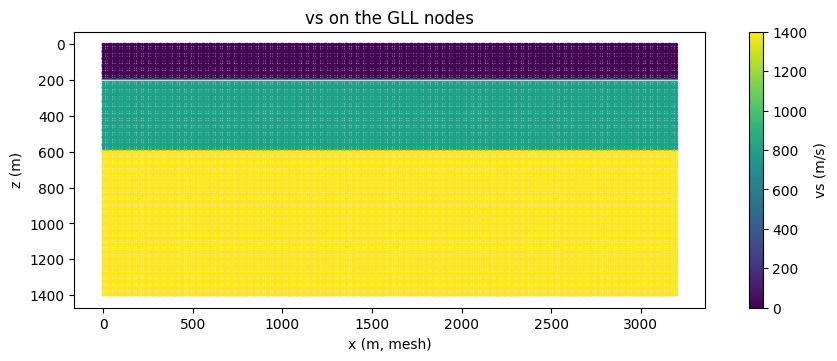

In [4]:
mesh = solver.mesh
z = mesh.z_e                                            # (E, ngll, ngll), metres
z_centre = z.mean(dim=(1, 2), keepdim=True)
fluid = (z_centre < z_sea).expand_as(z)                 # per element
deep = z >= z_layer

vp  = torch.where(fluid, 1500.0, torch.where(deep, 2800.0, 2000.0))
vs  = torch.where(fluid, 0.0,    torch.where(deep, 1400.0, 800.0))
rho = torch.where(fluid, 1000.0, torch.where(deep, 2200.0, 1900.0))
models = [m.float().to(device) for m in (vp, vs, rho)]
print('model on the GLL nodes:', tuple(vp.shape), '| fluid elements:',
      int(fluid[:, 0, 0].sum()), 'of', mesh.n_elements)

fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
sc = ax.scatter(mesh.x_e.flatten().cpu(), mesh.z_e.flatten().cpu(), c=vs.flatten().cpu(),
                s=1, cmap='viridis')
ax.axhline(z_sea, color='w', lw=0.5); ax.invert_yaxis(); ax.set_aspect('equal')
ax.set_xlabel('x (m, mesh)'); ax.set_ylabel('z (m)'); ax.set_title('vs on the GLL nodes')
fig.colorbar(sc, ax=ax, label='vs (m/s)')
plt.show()

## 4. Hydrophones and ocean-bottom nodes

A pressure source 20 m below the sea surface (the equation's default source is the
fluid potential). Two receiver lines in one call: hydrophones 40 m deep in the
water and ocean-bottom nodes 10 m into the sea floor. `receiver_type=['p', 'vx', 'vz']`
records all three components at every receiver; pressure is meaningful in the
water and the velocities in the solid (they are zero in the water), so each line
takes its own components.

In [5]:
rx = np.arange(0, shape[1], 2)
hydrophones = np.stack([rx, np.full_like(rx, 4)], axis=1)
nodes = np.stack([rx, np.full_like(rx, nw + 1)], axis=1)
receivers = np.concatenate([hydrophones, nodes])[None]        # (1, 2 * nrec, 2)

with torch.no_grad():
    seis = solver(wavelet, src, receivers, models=models)
print('record', tuple(seis.shape), ' components', solver.receiver_type)
nr = len(rx)
p_hyd = seis[0, :, :nr, 0].cpu().numpy()
vx_obn = seis[0, :, nr:, 1].cpu().numpy()
vz_obn = seis[0, :, nr:, 2].cpu().numpy()

record (1, 2800, 242, 3)  components ['p', 'vx', 'vz']


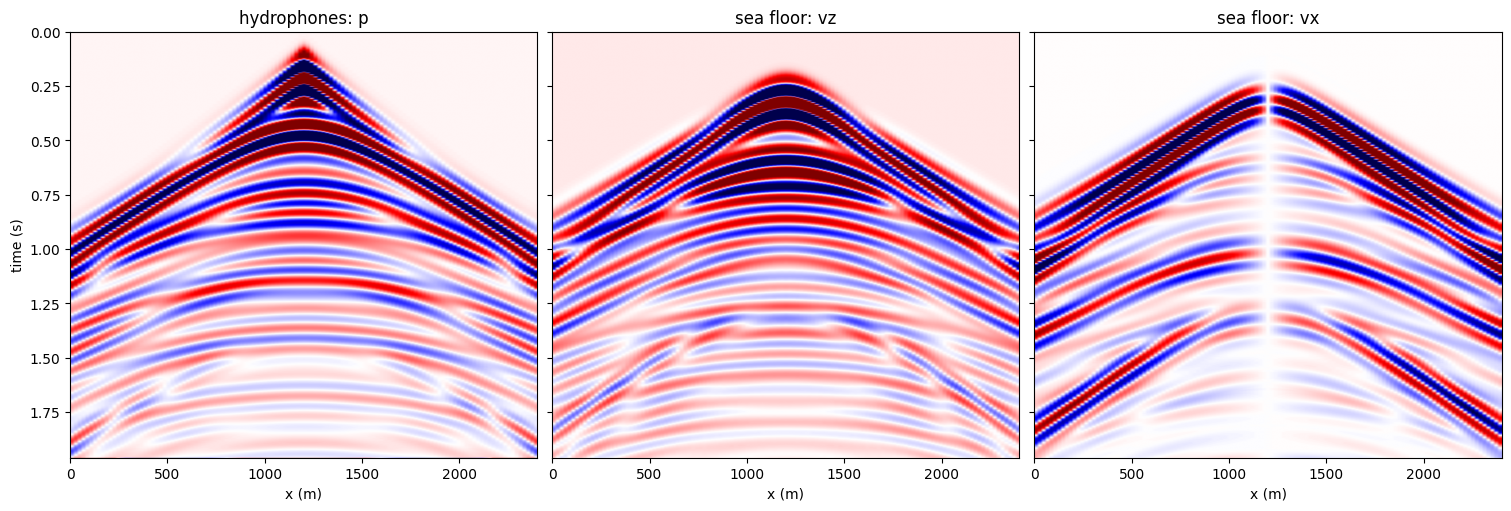

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, constrained_layout=True)
for ax, g, title in zip(axes, [p_hyd, vz_obn, vx_obn],
                        ['hydrophones: p', 'sea floor: vz', 'sea floor: vx']):
    lo, hi = np.percentile(g[g != 0], [2, 98])
    ax.imshow(g, cmap='seismic', vmin=lo, vmax=hi, aspect='auto',
              extent=[rx[0] * dh, rx[-1] * dh, nt * dt, 0])
    ax.set_title(title); ax.set_xlabel('x (m)')
axes[0].set_ylabel('time (s)')
plt.show()

The hydrophones see the direct wave, the sea-floor reflection and the
water-layer reverberations (a period of `2 x 200 m / 1500 m/s ≈ 0.27 s`). The
sea-floor nodes record the same reverberations on `vz`; `vx` shows the
horizontal motion of the waves in the solid, and is zero straight below the
source, by symmetry. The source is 180 m above the sea floor, so the interface
(Scholte) wave, which decays away from the sea floor within about a wavelength,
is hardly excited here; a source or receiver close to the sea floor would see
it.

## 5. The wavefield

Snapshots (eager) hold each domain's own field: the potential `chi` in the
water, the displacement `u_x`, `u_z` in the solid. We show the vertical
displacement at 1.2 s, and blank the water, where it is not defined.

sweep: torch.compile is compiling the AcousticElasticSEM2D step for a 101x241 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


snapshot fields ['chi', 'u_x', 'u_z'] (1, 3, 1, 1, 141, 321)


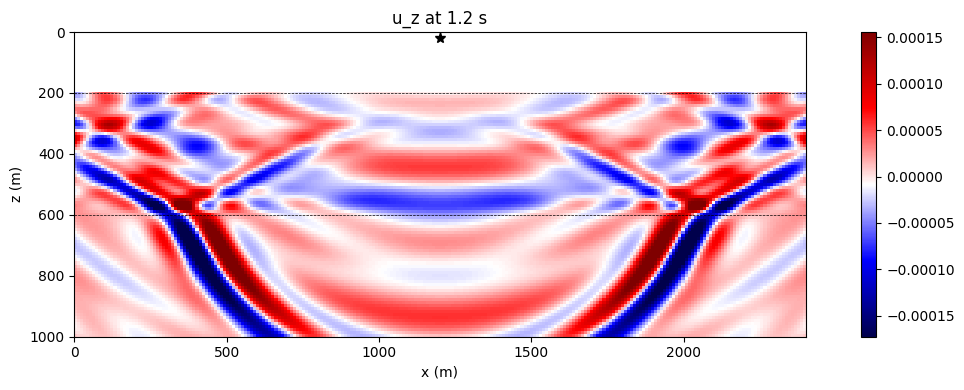

In [7]:
solver_e = PropSEM(AcousticElasticSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                   abcn=40, free_surface=True, f_dominant=f0,
                   receiver_type=['p', 'vx', 'vz'], impl='eager', device=device)
step = int(round(1.2 / dt))
with torch.no_grad():
    _, snaps = solver_e(wavelet, src, receivers, models=models,
                        return_wavefield=True, snapshot_times=[step])
print('snapshot fields', solver_e.snapshot_fields, tuple(snaps.shape))
uz = snaps[0, solver_e.snapshot_fields.index('u_z'), 0, 0].numpy()
uz = uz[:shape[0], 40:40 + shape[1]]                          # crop the C-PML
uz[:nw] = np.nan                                              # the water
lo, hi = np.nanpercentile(uz[uz != 0], [1, 99])
plt.figure(figsize=(12, 4))
plt.imshow(uz, cmap='seismic', vmin=lo, vmax=hi,
           extent=[0, (shape[1] - 1) * dh, (shape[0] - 1) * dh, 0])
plt.axhline(z_sea, color='k', lw=0.5, ls='--'); plt.axhline(z_layer, color='k', lw=0.5, ls='--')
plt.plot(src[0, 0] * dh, src[0, 1] * dh, 'k*', ms=8)
plt.xlabel('x (m)'); plt.ylabel('z (m)'); plt.title('u_z at 1.2 s')
plt.colorbar(); plt.tight_layout(); plt.show()

## Summary

- `AcousticElasticSEM2D` takes `[vp, vs, rho]`; `vs = 0` marks the fluid, element by
  element, and the sea floor must lie on element edges.
- Give the models on the GLL nodes, `(n_elements, ngll, ngll)`, built from
  `solver.mesh.x_e` / `z_e` (the mesh includes the absorbing layer).
- `receiver_type=['p', 'vx', 'vz']` records hydrophone and sea-floor components in
  one call; it runs on `impl='c'`, with shot batching and boundary saving.

Next: [SEM basics · 7 — a 3-D model](../56_sem_3d/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="55_sem_fluid_solid.ipynb" download><code>55_sem_fluid_solid.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/55_sem_fluid_solid.ipynb">view on GitHub</a></p>